In [4]:
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.preprocessing import image
!pip install importlib_resources tensorflow_datasets

In [5]:
ds,info=tdfs.load("plant_village",split+"train",as_supervised=True,with_info=True)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.0BOHRM_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.


In [8]:
names=info.features["label"].names
healthy_ids=tf.constant([i for i, n in enumerate(names) if n.endswith("healthy")],dtype=tf.int64)

In [11]:
def prep(x,y):
  x=tf.image.resize(x,(128,128))/255.0
  is_healthy=tf.reduce_any(tf.equal(y,healthy_ids))
  return x,tf.cast(is_healthy,tf.float32)

In [12]:
ds=ds.map(prep).shuffle(1000,seed=1,reshuffle_each_iteration=False)

In [16]:
total=info.splits["train"].num_examples
train_size=int(0.8 * total)
train=ds.take(train_size).batch(32)
test=ds.skip(train_size).batch(32)

In [18]:
model=Sequential([
    Conv2D(32,(3,3),activation="relu",input_shape=(128,128,3)),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(64,(3,3),activation="relu"),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(128,(3,3),activation="relu"),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(512,activation="relu"),
    Dense(1,activation="sigmoid")
])

In [21]:
model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])

In [24]:
model.fit(train,epochs=3)

Epoch 1/3
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 46s 33ms/step - accuracy: 0.9978 - loss: 0.0084
Epoch 2/3
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 35s 25ms/step - accuracy: 0.9985 - loss: 0.0055
Epoch 3/3
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 37s 27ms/step - accuracy: 0.9984 - loss: 0.0058


In [25]:
loss,accuracy=model.evaluate(test)

340/340 ━━━━━━━━━━━━━━━━━━━━ 37s 29ms/step - accuracy: 0.9869 - loss: 0.0666


In [31]:
img=image.load_img("image (1).jpg",target_size=(128,128))
img_array=image.img_to_array(img) /255.0
img_array=tf.expand_dims(img_array, axis=0)
p=model.predict(img_array)[0][0]
print("Healthy" if p > 0.5 else "Diseased")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
Diseased


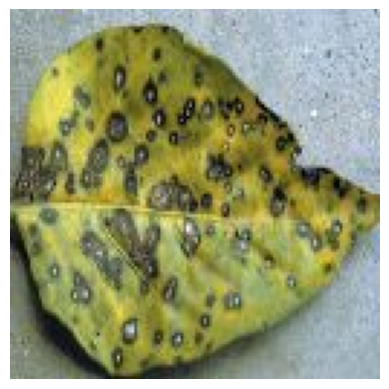

In [33]:
import matplotlib.pyplot as plt
img = image.load_img("image (1).jpg", target_size=(128, 128))
plt.imshow(img)
plt.axis("off")
plt.show()